In [2]:
import pandas as pd
import plotnine as pn
import numpy as np
from scipy.stats import beta

import polars as pl
import itables
from itables import init_notebook_mode
init_notebook_mode(all_interactive=True)
import itables.options as opt
opt.lengthMenu = [10, 20, 50, 100]
opt.pageLength = 20   # in newer versions; otherwise use show(..., pageLength=20)
import polars.selectors as cs
from scipy.stats import mannwhitneyu
import os
import scipy.stats as stats



In [3]:
import sys
sys.path.append("/home/a379i/Scripts")   # path to folder containing the python file

from utils.load_gtf_cgc_dresden import *
from ProteinExpression.load_pr_data import *
from Variants.add_missing_acmg import *
from utils.util_functions import *



In [4]:
dresden_germline = (pl.scan_parquet("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/vcf/dresden_annotations/germline/germline_aggregated_predisp_cgc_tinda.parquet")
                    .with_columns(
                            cs.starts_with("SpliceAI_pred_DS_").cast(pl.Float64, strict=False)
                    ).filter((pl.col("PID").is_in(sa[sa["Diag"]!= "Unstranded_data"]["pid"])))     
                    .collect(engine="streaming")        
                  ).to_pandas()
# dresden_germline


dresden_germline["germline_max_spliceai_score"] = dresden_germline[["SpliceAI_pred_DS_AL", "SpliceAI_pred_DS_AG", 
    "SpliceAI_pred_DS_DG", "SpliceAI_pred_DS_DL"
]].max(axis=1)
dresden_germline = add_missing_acmgs(dresden_germline)

dresden_germline = dresden_germline.rename(columns = {"#CHROM": "germline_chrom", "POS": "germline_POS", "REF": "germline_REF", "ALT": "germline_ALT", "STRAND": "germline_STRAND"}) 


dresden_germline = dresden_germline.drop_duplicates(subset=["PID", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "Gene"])

dresden_germline['variant_class'] = dresden_germline['germline_Consequence'].str.contains(
    coding_pattern, 
    regex=True, 
    na=False
).map({True: 'Coding', False: 'Non-coding'})




In [5]:
dresden_somatic = (pl.scan_parquet("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/vcf/dresden_annotations/somatic/somatic_aggregated_predisp_cgc.parquet")
                    .with_columns(
                            cs.starts_with("SpliceAI_pred_DS_").cast(pl.Float64, strict=False)
                    )
                   .filter((pl.col("PID").is_in(sa[sa["Diag"]!= "Unstranded_data"]["pid"])))
                           
                    .collect(engine="streaming")
                    
                  ).to_pandas()
# dresden_somatic

dresden_somatic["somatic_max_spliceai_score"] = dresden_somatic[["SpliceAI_pred_DS_AL", "SpliceAI_pred_DS_AG", 
    "SpliceAI_pred_DS_DG", "SpliceAI_pred_DS_DL"
]].max(axis=1)

dresden_somatic = dresden_somatic.rename(columns = {"#CHROM": "somatic_chrom", "POS": "somatic_POS", "REF": "somatic_REF", "ALT": "somatic_ALT", "STRAND": "somatic_STRAND"}) 
dresden_somatic['variant_class'] = dresden_somatic['somatic_Consequence'].str.contains(
    coding_pattern, 
    regex=True, 
    na=False
).map({True: 'Coding', False: 'Non-coding'})

dresden_somatic_coding = dresden_somatic[dresden_somatic["variant_class"] == "Coding"]

dresden_somatic_coding = dresden_somatic_coding.drop_duplicates(subset=["PID", "somatic_chrom", "somatic_POS", "somatic_REF", "somatic_ALT", "Gene"])



                  


# gene expression

In [6]:
or_res_path = "/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/py_outrider_runs/all_cohorts/oht_cov_diag_lr_0_0001_epoc200_gpu/or_variants_interesting_genes_padjust_cnv.parquet"
needed_cols = ["sampleID", "zScore", "pValue", "padjust", "IMPACT", "geneID",  "geneID_short",
               "padjust_predisp", "padjust_predisp_extended", "CNV", "padjust_genes_of_interest"]


py_or_res_all = pl.scan_parquet(or_res_path).select(needed_cols).filter((pl.col("geneID_short").is_in(genes_of_interest["geneID_short"]))).collect().to_pandas()
#
# or_res_path = "/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/py_outrider_runs/all_cohorts/oht_cov_diag_lr_0_0001_epoc200_gpu/or_variants_tsg_predisp_padjust_cnv.parquet"


# py_or_res_all = pl.scan_parquet(or_res_path).collect().to_pandas()


py_or_res_all["Method"] = "OUTRIDER"

# py_or_res_all = py_or_res_all[(py_or_res_all["padjust_predisp_extended"] <= 0.05) | (py_or_res_all["padjust"] <= 0.05)]


py_or_res_all = pd.merge(py_or_res_all, sa[["pid", "Diag", "seq_type", "Oncotree Code", "Oncotree Text", "nct_pid", "Tumorzellgehalt (Bioinformatik)"]], left_on="sampleID", right_on="pid")
py_or_res_all = pd.merge(py_or_res_all, gene_annot_dt.drop(columns="geneID_short"), left_on="geneID", right_on="gene_id", how="left")

py_or_res_all = py_or_res_all.sort_values("pValue")
py_or_res_all = py_or_res_all.drop_duplicates(subset=["sampleID", "geneID_short"])




In [7]:
# py_or_res_aberrant["key"] = py_or_res_aberrant["sampleID"] +  "." + py_or_res_aberrant["nct_pid"].str.split("_").str[1]
py_or_res_all = py_or_res_all.merge(dresden_germline , left_on=["geneID_short", "sampleID"], right_on=["Gene", "PID"], how="left")
py_or_res_all = py_or_res_all.merge(dresden_somatic_coding , left_on=["geneID_short", "sampleID"], right_on=["Gene", "PID"], how="left")


# py_or_res_all["germline_somatic_IMPACT"] = py_or_res_all["germline_IMPACT"]
# py_or_res_all.loc[py_or_res_all["somatic_IMPACT"].str.contains("HIGH"), "germline_somatic_IMPACT"] = "HIGH"


py_or_res_all["Outlier status"] = False
py_or_res_all.loc[py_or_res_all["padjust_genes_of_interest"] <= 0.1, "Outlier status"] = True

In [10]:
py_or_res_all["gene_sample"] = py_or_res_all["geneID_short"] + "_" + py_or_res_all["sampleID"]

In [11]:
promoterAI_vars = py_or_res_all[py_or_res_all["germline_promoterAI"].notna()]

p = (pn.ggplot(promoterAI_vars) +
     pn.geom_point(pn.aes(x="germline_promoterAI", y="zScore", color="CNV")) +
     pn.theme_bw()
)
p

In [14]:
coding_var_gene_samples = set(promoterAI_vars[promoterAI_vars["variant_class_x"] == "Coding"]["gene_sample"].unique())
coding_var_gene_samples = list(coding_var_gene_samples.union(set(promoterAI_vars[promoterAI_vars["variant_class_y"] == "Coding"]["gene_sample"].unique())))
len(coding_var_gene_samples)

6713

In [31]:
promoterAI_only_non_coding.shape



(9587, 235)

In [19]:
promoterAI_vars[promoterAI_vars["somatic_POS"].notna()][["germline_POS", "somatic_POS", "germline_Consequence", "somatic_Consequence"]]

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [1]:
promoterAI_only_non_coding = promoterAI_vars[(~promoterAI_vars["gene_sample"].isin(coding_var_gene_samples)) & (promoterAI_vars["CNV"] == "No CNV")]

r, p_val = stats.spearmanr(
    promoterAI_only_non_coding["germline_promoterAI"],
    promoterAI_only_non_coding["zScore"],
)

p = (pn.ggplot(promoterAI_only_non_coding) +
     pn.geom_point(pn.aes(x="germline_promoterAI", y="zScore")) +
     pn.labs(title=f"Restricted to gene-samples w/o any protein coding/cnv variants\nSpearman r = {r:.3f}") +
     pn.theme_bw()
)
p

NameError: name 'promoterAI_vars' is not defined

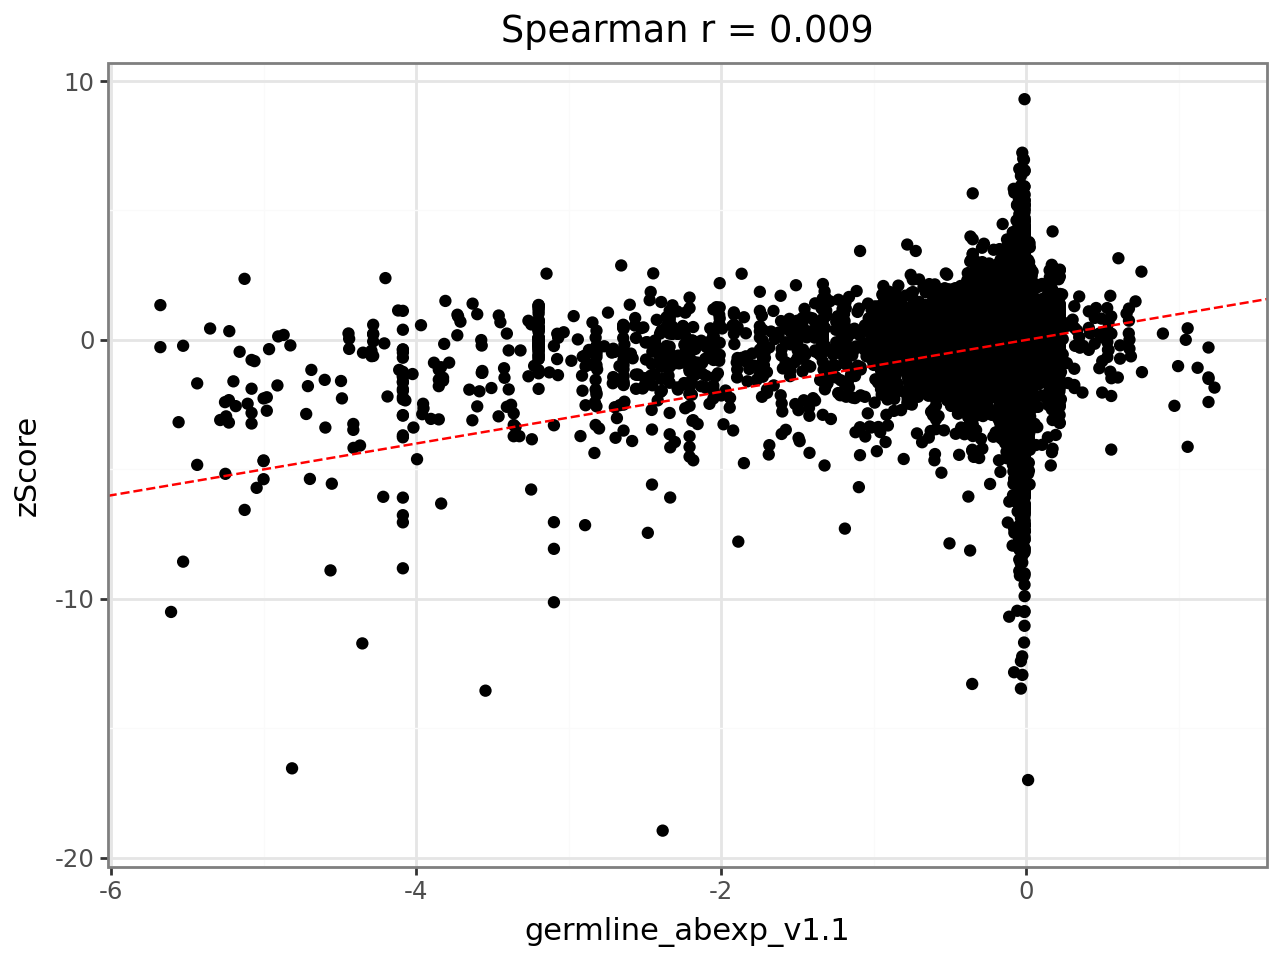

In [21]:
abexp_vars = py_or_res_all[(py_or_res_all["germline_abexp_v1.1"].notna()) & (py_or_res_all["CNV"] == "No CNV") & (py_or_res_all["variant_class_y"] != "Coding")]
r, p_val = stats.spearmanr(
    abexp_vars["germline_abexp_v1.1"],
    abexp_vars["zScore"],
)

p2 = (pn.ggplot(abexp_vars) +
     pn.geom_point(pn.aes(x="germline_abexp_v1.1", y="zScore")) +

    pn.labs(title=f"Spearman r = {r:.3f}") +

     pn.theme_bw()
)
p2

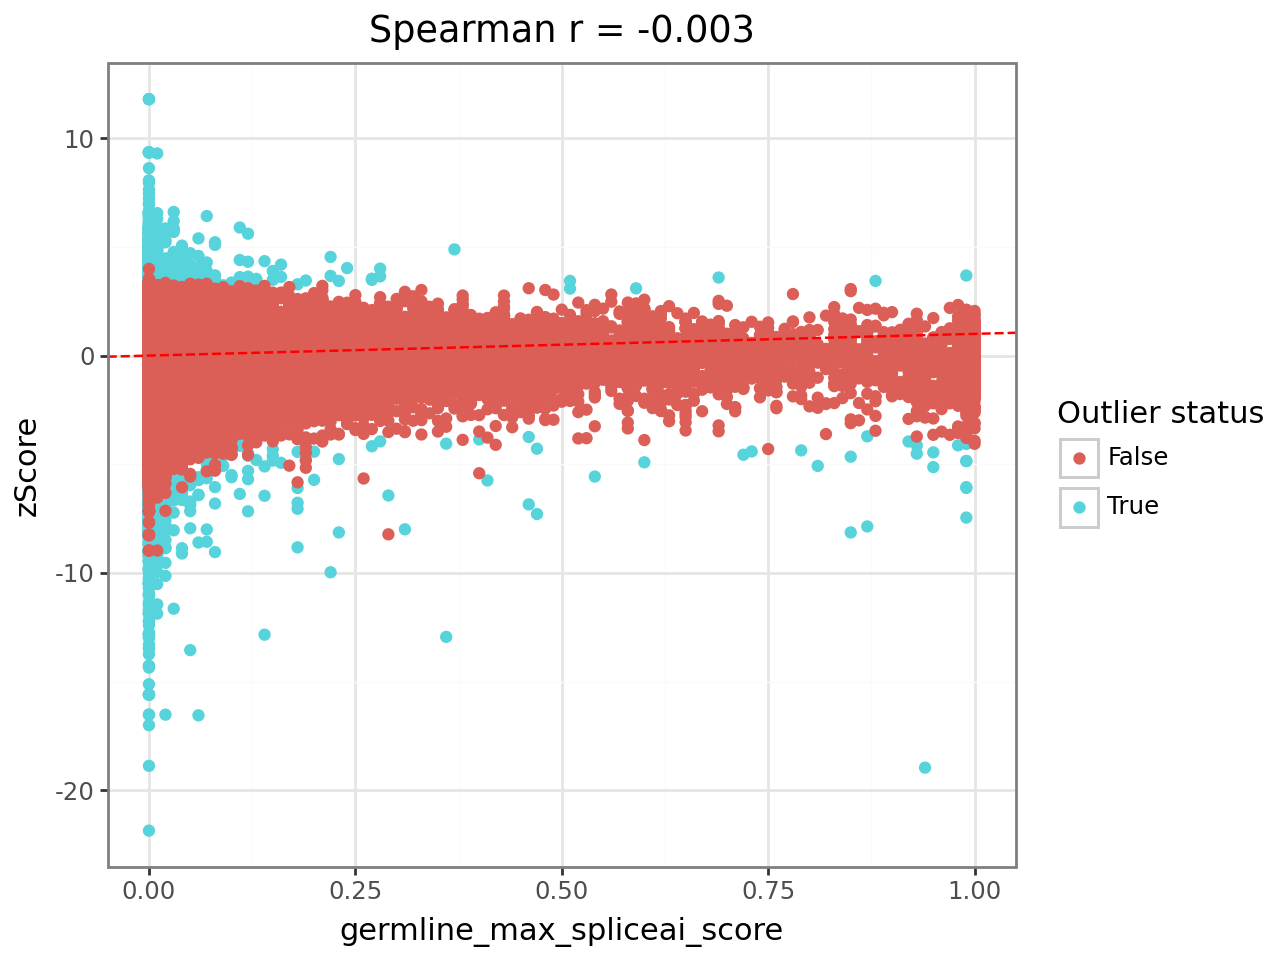

In [22]:
absplice_vars = py_or_res_all[(py_or_res_all["germline_max_spliceai_score"].notna()) & (py_or_res_all["CNV"] == "No CNV") & (py_or_res_all["variant_class_y"] != "Coding")]
r, p_val = stats.spearmanr(
    absplice_vars["germline_max_spliceai_score"],
    absplice_vars["zScore"],
)

p2 = (pn.ggplot(absplice_vars) +
     pn.geom_point(pn.aes(x="germline_max_spliceai_score", y="zScore", color="Outlier status")) +
    pn.geom_abline(intercept=0, slope=1, color="red", linetype="dashed") +

    pn.labs(title=f"Spearman r = {r:.3f}") +

     pn.theme_bw()
)
p2

# Protein Expression

In [6]:
pr_output_name = "cov_gaussian_gs_lr_0_001_epoc2000_noInitPCA"

pr_res_all = pl.scan_parquet("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/protrider_runs/output_" + pr_output_name + "/pr_variants_tsg_predisp_padjust_cnv.parquet").filter((pl.col("geneID_short").is_in(genes_of_interest["geneID_short"]))).collect(engine="streaming").to_pandas()
pr_res_all = pd.merge(pr_res_all, dresden_dt_cgc[["geneID_short", "ROLE_IN_CANCER", "predisposition_gene"]], on="geneID_short", how="left")
pr_res_all = pd.merge(pr_res_all, sa[["pid", "Diag", "seq_type", "Oncotree Code", "Oncotree Text", "nct_pid", "Tumorzellgehalt (Bioinformatik)"]], left_on="sampleID", right_on="pid")
pr_res_all["Method"] = "PROTRIDER"


In [9]:
pr_res_all = pr_res_all.merge(dresden_germline, left_on=["sampleID", "geneID_short"], right_on=["PID", "Gene"], how="left")

pr_res_all = pr_res_all.merge(dresden_somatic.drop(columns=["ref_x", "ref_y"]), left_on=["sampleID", "geneID_short"], right_on=["PID", "Gene"], how="left")




/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/envs/protrider_env/lib/python3.13/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 1725 rows containing missing values.


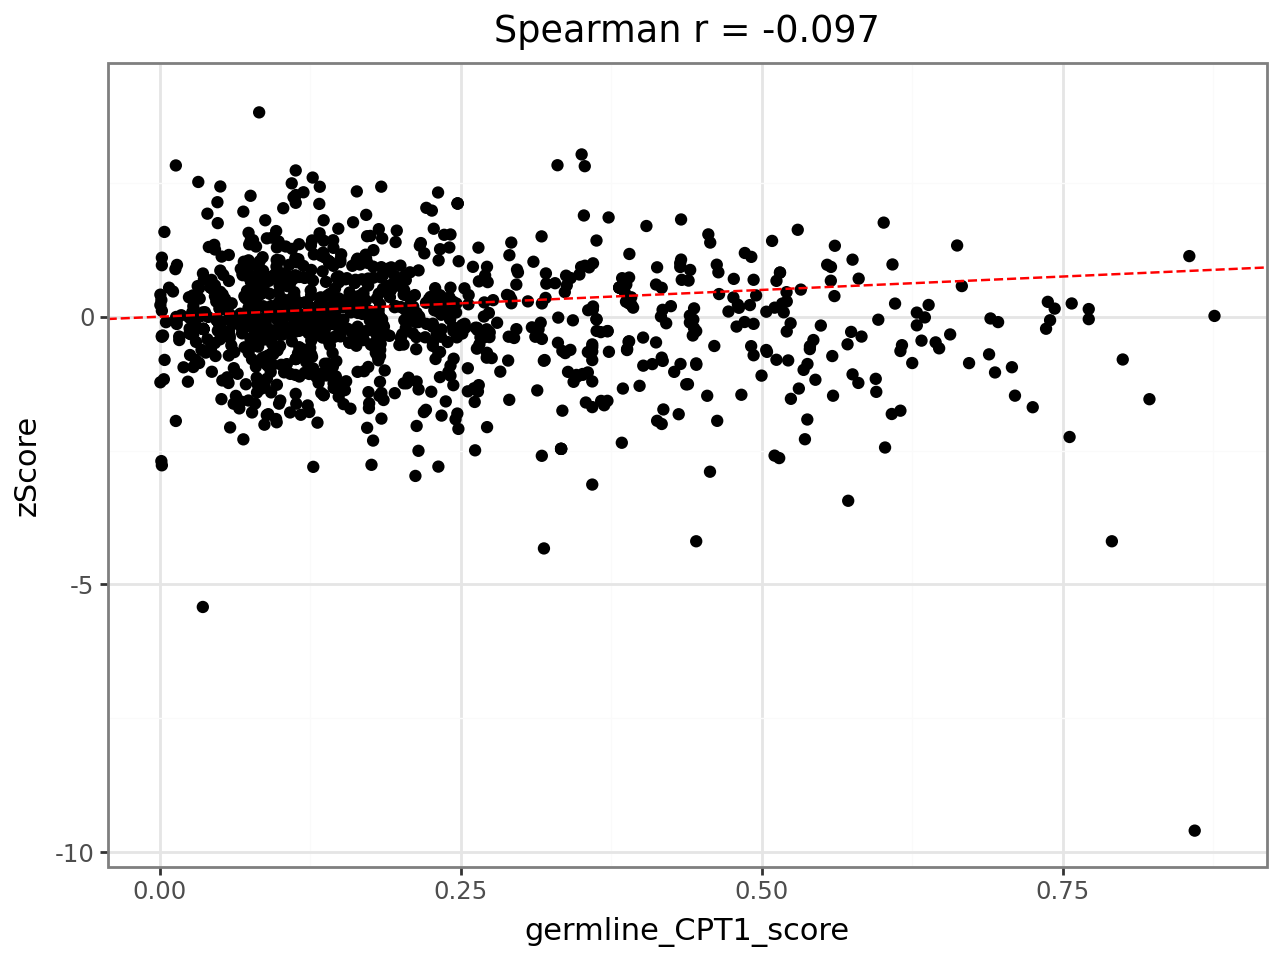

In [16]:
missense_vars = pr_res_all[pr_res_all["germline_Consequence"].str.contains("missense")]

r, p_val = stats.spearmanr(
    missense_vars["germline_CPT1_score"],
    missense_vars["zScore"],
    nan_policy="omit",
)


p = (pn.ggplot(missense_vars) +
     
     pn.geom_point(pn.aes(x="germline_CPT1_score", y="zScore",)) +
    pn.labs(title=f"Spearman r = {r:.3f}") +
     pn.theme_bw()
)
p

/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/envs/protrider_env/lib/python3.13/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 351 rows containing missing values.


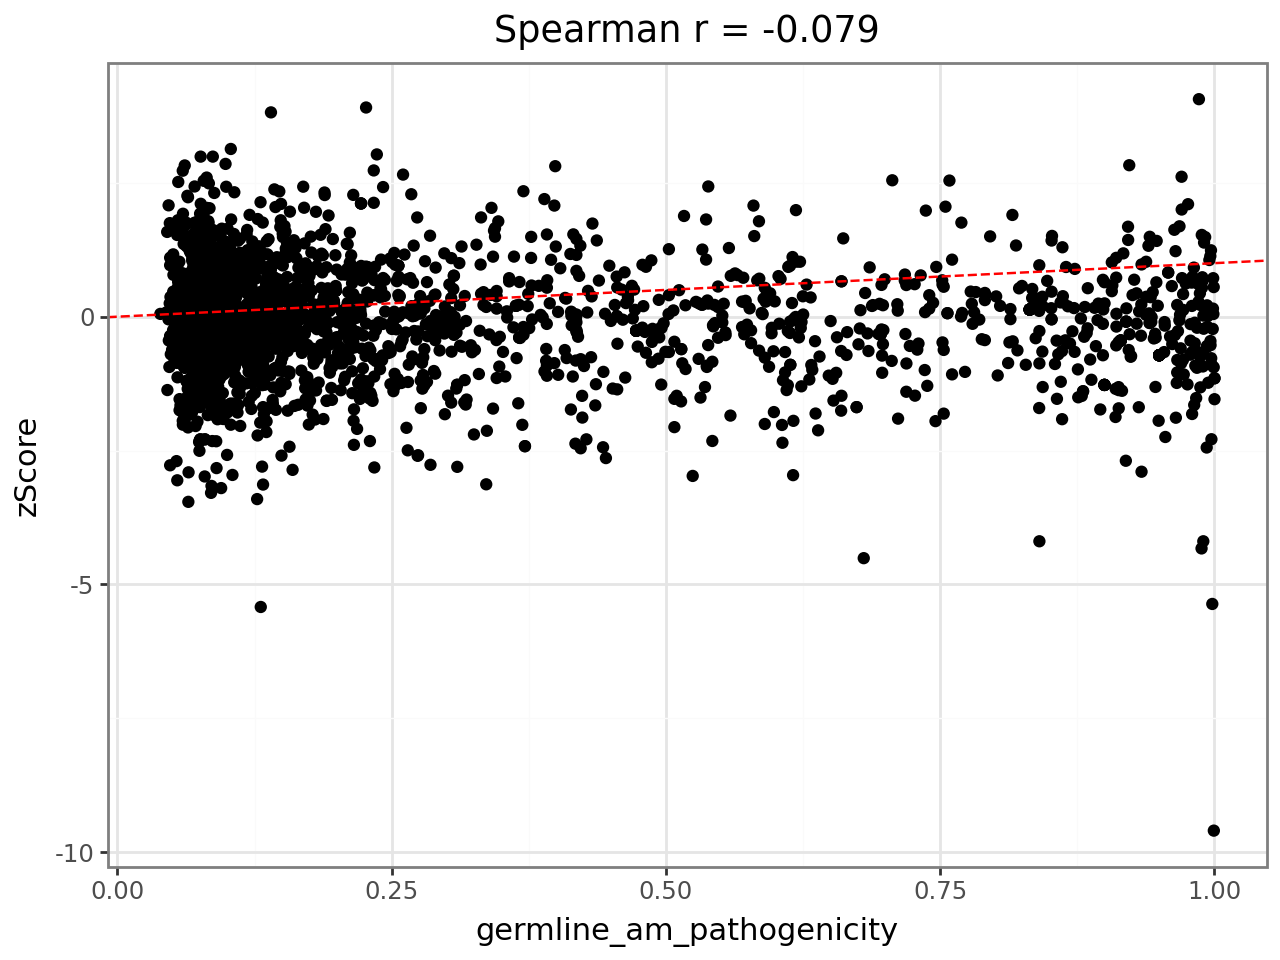

In [21]:
missense_vars["germline_am_pathogenicity"] = pd.to_numeric(
    missense_vars["germline_am_pathogenicity"], errors="coerce"
)

r, p_val = stats.spearmanr(
    missense_vars["germline_am_pathogenicity"],
    missense_vars["zScore"],
    nan_policy="omit",
)
p = (pn.ggplot(missense_vars) +
     pn.geom_point(pn.aes(x="germline_am_pathogenicity", y="zScore")) +
     pn.labs(title=f"Spearman r = {r:.3f}") +
     pn.theme_bw()
)
p

/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/envs/protrider_env/lib/python3.13/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 204 rows containing missing values.


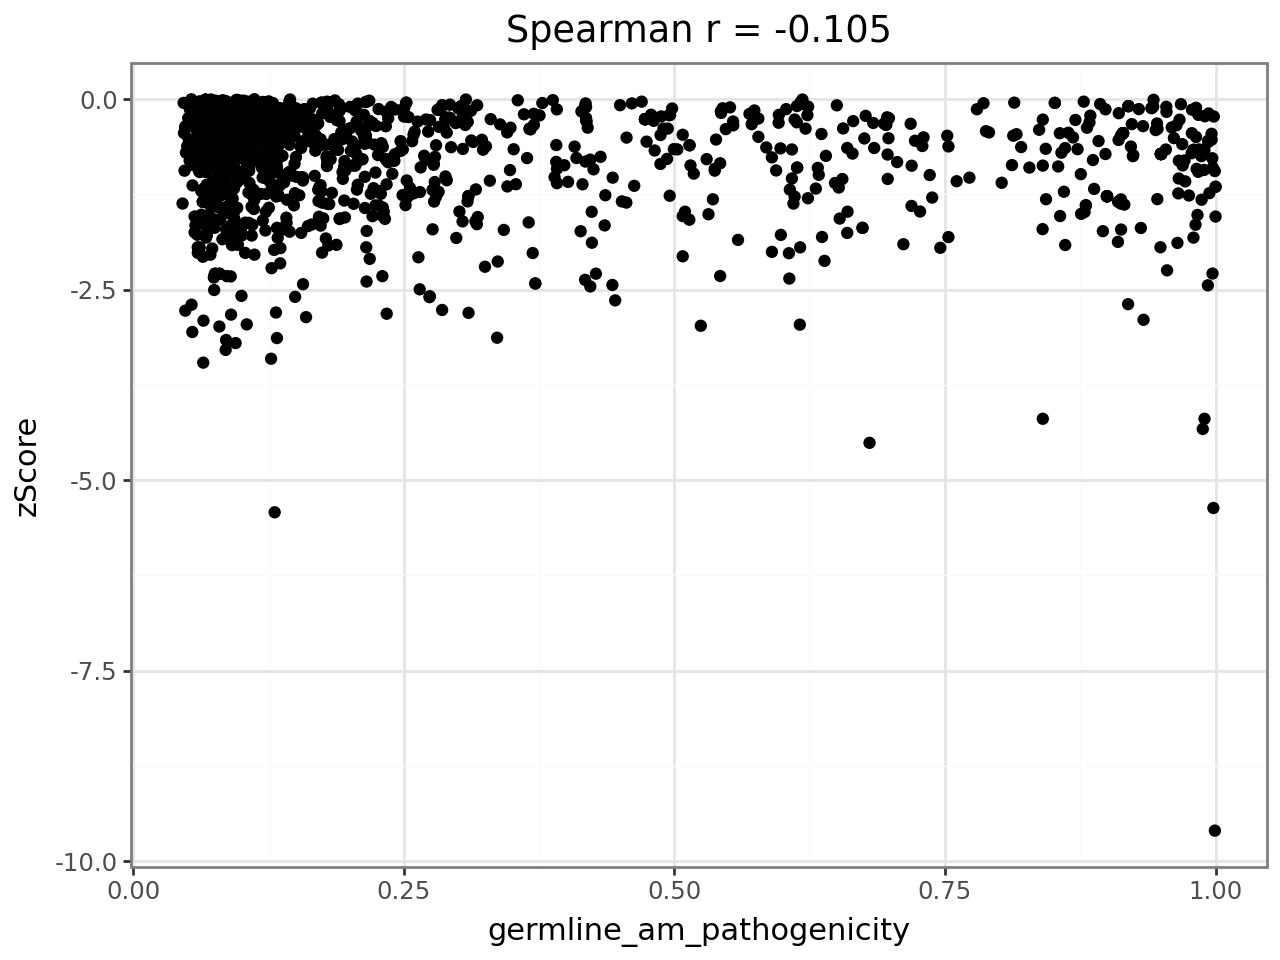

In [23]:
missense_vars["germline_am_pathogenicity"] = pd.to_numeric(
    missense_vars["germline_am_pathogenicity"], errors="coerce"
)

r, p_val = stats.spearmanr(
    missense_vars[missense_vars["zScore"] <= 0]["germline_am_pathogenicity"],
    missense_vars[missense_vars["zScore"] <= 0]["zScore"],
    nan_policy="omit",
)
p = (pn.ggplot(missense_vars[missense_vars["zScore"] <= 0]) +
     pn.geom_point(pn.aes(x="germline_am_pathogenicity", y="zScore")) +
     pn.labs(title=f"Spearman r = {r:.3f}") +
     pn.theme_bw()
)
p